# Analyse Exploratoire - Dataset Final

Analyse complète et sans erreurs du dataset final de commentaires YouTube en Darija.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Détecter le chemin du projet
project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent

print(f"📁 Project root: {project_root}")

📁 Project root: c:\Users\elham\Desktop\youtube-sentiment-analysis


In [42]:
# ÉTAPE 1: CHARGER LE DATASET
print("\n" + "="*70)
print("ÉTAPE 1: CHARGEMENT DU DATASET")
print("="*70)

df_path = project_root / 'data' / 'labeled' / 'final_filtered.json'

if not df_path.exists():
    raise FileNotFoundError(f"❌ Fichier non trouvé: {df_path}")

df = pd.read_json(df_path)
print(f"✅ Dataset chargé avec succès!")
print(f"   📊 Dimension: {len(df):,} lignes × {df.shape[1]} colonnes")
print(f"   📋 Colonnes: {list(df.columns)}")


ÉTAPE 1: CHARGEMENT DU DATASET
✅ Dataset chargé avec succès!
   📊 Dimension: 43,412 lignes × 6 colonnes
   📋 Colonnes: ['comment_id', 'text_clean', 'sentiment', 'char_length', 'word_count', 'has_noise']


In [43]:
# ÉTAPE 2: APERÇU DES DONNÉES
print("\n" + "="*70)
print("ÉTAPE 2: APERÇU DES DONNÉES")
print("="*70)

print("\nPremières lignes:")
display(df.head(10))

print("\nInfo détaillées:")
df.info()


ÉTAPE 2: APERÇU DES DONNÉES

Premières lignes:


,comment_id,text_clean,sentiment,char_length,word_count,has_noise
0,UgwodTeGOvTeIGNux8Z4AaABAg,مقرلتيناش كيفاش مديرو مليون دولار,Neutre,33,5,False
1,Ugw9ANN-50l1Di_FLQp4AaABAg,lah y barek concept nadi kat wa33i shabab,Positif,41,8,False
2,UgynNafjO6kDQRemBZ14AaABAg,الموضوع كيف تتحرر من وسايل التواصل الاجتماعي,Neutre,44,7,False
3,UgzmAQ1zH4yG2_-enKJ4AaABAg,فاش شفت السطوري و الترويج قلت غا تكون شي حاجه ...,Positif,81,16,False
4,UgzwHC0zOu9rFQPvtBt4AaABAg,رياله وصلات خويا سيمو,Neutre,21,4,False
5,UgyVxDZK0uCKMwHNri54AaABAg,madghetch 3la rassek bach der lfloss dghet 3la...,Neutre,96,16,False
6,UgzqgHYlIL3eEHItU-V4AaABAg,بارك الله فيكم وجزاكم خيرا واذكر نفسي والجميع ...,Positif,65,10,False
7,Ugz1i1DLriu0IQUM9tV4AaABAg,انا ما كنتش ضايرلك ابونني,Neutre,25,5,False
8,UgxuWxhcEza0KyENpmF4AaABAg,القناعه كنز لا يفني,Neutre,19,4,False
9,Ugy--sPlf-MWe7eVNkt4AaABAg,تحياتي لك خويا سيمو سدراتي شي جميل,Positif,34,7,False



Info détaillées:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43412 entries, 0 to 43411
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   comment_id   43412 non-null  object
 1   text_clean   43412 non-null  object
 2   sentiment    43412 non-null  object
 3   char_length  43412 non-null  int64 
 4   word_count   43412 non-null  int64 
 5   has_noise    43412 non-null  bool  
dtypes: bool(1), int64(2), object(3)
memory usage: 1.7+ MB


In [44]:
# ÉTAPE 3: STATISTIQUES DESCRIPTIVES
print("\n" + "="*70)
print("ÉTAPE 3: STATISTIQUES DESCRIPTIVES")
print("="*70)

# Afficher les colonnes numériques uniquement
display(df.describe())


ÉTAPE 3: STATISTIQUES DESCRIPTIVES


,char_length,word_count
count,43412.000000,43412.000000
mean,47.950244,8.999079
std,43.503549,8.058350
min,2.000000,1.000000
25%,20.000000,4.000000
50%,33.000000,6.000000
75%,59.000000,11.000000
max,408.000000,80.000000


In [46]:
# ÉTAPE 5: DOUBLONS
print("\n" + "="*70)
print("ÉTAPE 5: VÉRIFICATION DES DOUBLONS")
print("="*70)

# Important: exclure les colonnes avec listes (tokens) car elles ne sont pas hashable
columns_to_check = [c for c in df.columns if c != 'tokens']
n_dup = df[columns_to_check].duplicated().sum()

print(f"Nombre de doublons (excluant 'tokens'): {n_dup}")

if n_dup > 0:
    print(f"⚠️  {n_dup} doublons détectés. Suppression...")
    df = df.drop_duplicates(subset=columns_to_check).reset_index(drop=True)
    print(f"✅ Après suppression: {len(df):,} lignes")
else:
    print("✅ Aucun doublon détecté!")


ÉTAPE 5: VÉRIFICATION DES DOUBLONS
Nombre de doublons (excluant 'tokens'): 0
✅ Aucun doublon détecté!



ÉTAPE 6: DISTRIBUTION DES SENTIMENTS

Répartition des sentiments:


,Sentiment,Nombre,Pourcentage
0,Positif,15171,34.95
1,Neutre,14404,33.18
2,Negatif,13837,31.87


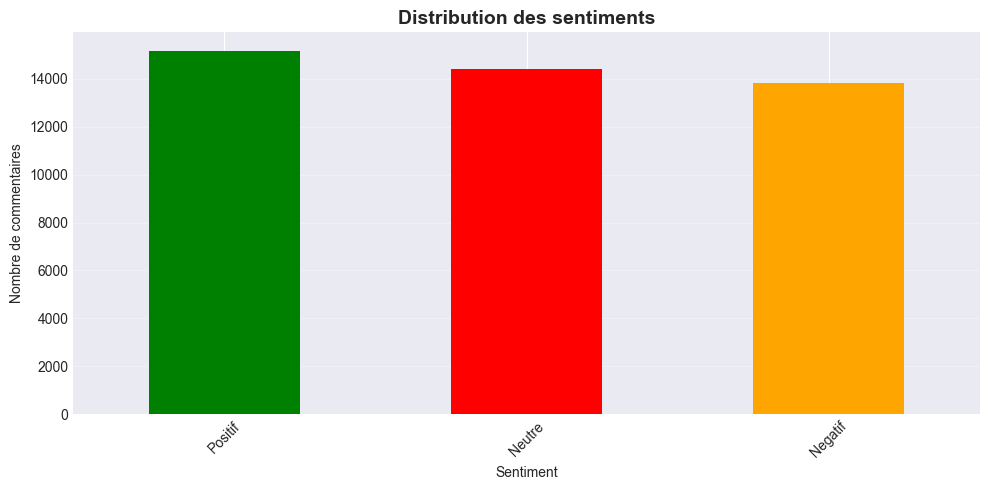

In [47]:
# ÉTAPE 6: DISTRIBUTION DES SENTIMENTS
print("\n" + "="*70)
print("ÉTAPE 6: DISTRIBUTION DES SENTIMENTS")
print("="*70)

sentiment_counts = df['sentiment'].value_counts()
sentiment_pct = df['sentiment'].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    'Sentiment': sentiment_counts.index,
    'Nombre': sentiment_counts.values,
    'Pourcentage': sentiment_pct.values.round(2)
})

print("\nRépartition des sentiments:")
display(summary)

# Graphique
fig, ax = plt.subplots(figsize=(10, 5))
sentiment_counts.plot(kind='bar', ax=ax, color=['green', 'red', 'orange'])
plt.title('Distribution des sentiments', fontsize=14, fontweight='bold')
plt.ylabel('Nombre de commentaires')
plt.xlabel('Sentiment')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

La distribution des sentiments est globalement équilibrée, avec une légère dominance des commentaires positifs. Les classes neutre et négative présentent des proportions proches, ce qui indique que le dataset ne souffre pas d’un fort déséquilibre de classes.


ÉTAPE 7: ANALYSE DE LA LONGUEUR DES TEXTES

Statistiques sur la longueur des textes:


,char_length,word_count
count,43412.00,43412.00
mean,47.95,9.00
std,43.50,8.06
min,2.00,1.00
25%,20.00,4.00
50%,33.00,6.00
75%,59.00,11.00
max,408.00,80.00


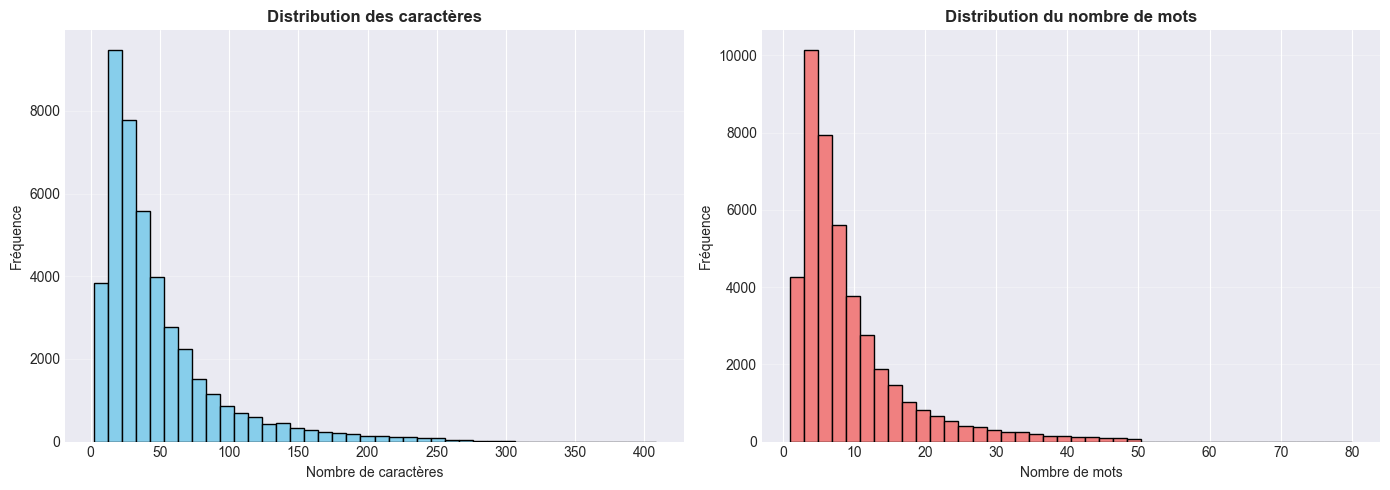

In [48]:

print("\n" + "="*70)
print("ÉTAPE 7: ANALYSE DE LA LONGUEUR DES TEXTES")
print("="*70)

# Déterminer la colonne de texte
text_col = 'text_clean' if 'text_clean' in df.columns else 'text'

# Calculer les métriques
df['char_length'] = df[text_col].astype(str).apply(len)
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

stats = df[['char_length', 'word_count']].describe().round(2)
print("\nStatistiques sur la longueur des textes:")
display(stats)

# Graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['char_length'], bins=40, color='skyblue', edgecolor='black')
axes[0].set_title('Distribution des caractères', fontweight='bold')
axes[0].set_xlabel('Nombre de caractères')
axes[0].set_ylabel('Fréquence')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(df['word_count'], bins=40, color='lightcoral', edgecolor='black')
axes[1].set_title('Distribution du nombre de mots', fontweight='bold')
axes[1].set_xlabel('Nombre de mots')
axes[1].set_ylabel('Fréquence')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


ÉTAPE 8: Analyse des emoji

📊 ÉTAPE 8: ANALYSE DES EMOJIS

📌 Répartition des emojis :
has_emoji
False    43412
Name: count, dtype: int64


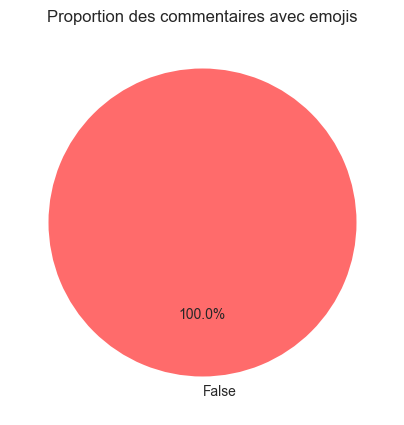

In [49]:

print("\n" + "="*70)
print("ÉTAPE 8: Analyse des emoji")
print("="*70)
import re
import matplotlib.pyplot as plt

print("\n" + "="*70)
print("📊 ÉTAPE 8: ANALYSE DES EMOJIS")
print("="*70)

# 🔍 Pattern emoji
emoji_pattern = re.compile(
    "[\U0001F600-\U0001F64F"
    "\U0001F300-\U0001F5FF"
    "\U0001F680-\U0001F6FF"
    "\U0001F1E0-\U0001F1FF"
    "\U00002700-\U000027BF"
    "]+",
    flags=re.UNICODE
)

# 📌 Détection
df["has_emoji"] = df["text_clean"].astype(str).apply(
    lambda x: bool(emoji_pattern.search(x))
)

# 📊 Comptage (MANQUAIT ICI ❗)
emoji_counts = df["has_emoji"].value_counts()

print("\n📌 Répartition des emojis :")
print(emoji_counts)

# 📈 Graphique PIE
plt.figure(figsize=(5,5))

emoji_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=["#ff6b6b", "#4ecdc4"],
    startangle=90
)

plt.title("Proportion des commentaires avec emojis")
plt.ylabel("")
plt.show()

VÉRIFICATION DU BRUIT TEXTUEL

In [50]:

print("\n" + "="*70)
print("ÉTAPE 9: VÉRIFICATION DU BRUIT TEXTUEL")
print("="*70)

import re

text_col = 'text_clean' if 'text_clean' in df.columns else 'text'

def check_noise(text):
    """Vérifier la présence de caractères spéciaux"""
    return bool(re.search(r'[^\w\s\u0600-\u06FF]', str(text)))

df['has_noise'] = df[text_col].apply(check_noise)
noise_count = df['has_noise'].value_counts()

print("\nRésumé du bruit:")
display(noise_count)

if noise_count.get(True, 0) > 0:
    pct = noise_count.get(True, 0) / len(df) * 100
    print(f"\n⚠️  {noise_count.get(True, 0)} commentaires ({pct:.2f}%) contiennent des caractères spéciaux")
else:
    print("\n✅ Aucun bruit détecté - dataset très propre!")


ÉTAPE 9: VÉRIFICATION DU BRUIT TEXTUEL

Résumé du bruit:


has_noise
False    43412
Name: count, dtype: int64


✅ Aucun bruit détecté - dataset très propre!


In [51]:

print("\n" + "="*70)
print("ÉTAPE 10: ÉCHANTILLON ALÉATOIRE DE COMMENTAIRES")
print("="*70)

sample = df.sample(n=min(15, len(df)), random_state=42)
display(sample[['text_clean', 'sentiment', 'char_length', 'word_count']])


ÉTAPE 10: ÉCHANTILLON ALÉATOIRE DE COMMENTAIRES


,text_clean,sentiment,char_length,word_count
18204,انا مشيت لدبي والكين جاتني في لفيديو حسن سيمو ...,Positif,72,15
4729,rah t9anti dawr diyalek f daba tzyan,Positif,36,7
20856,kayghawto ktar ma kay3tiw lma3loma w kadwiw f ...,Negatif,85,17
14348,zide jri ou zide jri wa5a wslti l9ima zid kmle...,Positif,133,26
1484,حبييت la manche de dressage des chiens,Positif,38,7
35580,اللي بغا العبوديه الله يطليه بها يا تريكه الجواري,Negatif,49,9
21616,بنتي ف عمرها عشر سنين و متفرقش بينها و بين الو...,Negatif,89,19
21773,اكبر عنصريين هما شلوح شلح تايبقي ها شلح,Negatif,39,8
3858,3lch manawich dir 39lk hh,Positif,25,5
10941,تاحد فيهم ما رابور هه,Negatif,21,5


Répartition des langues


 Répartition des langues :


language
darija (arabe)           24169
latin (fr/en/arabizi)    17578
mix (arabizi + arabe)     1665
Name: count, dtype: int64

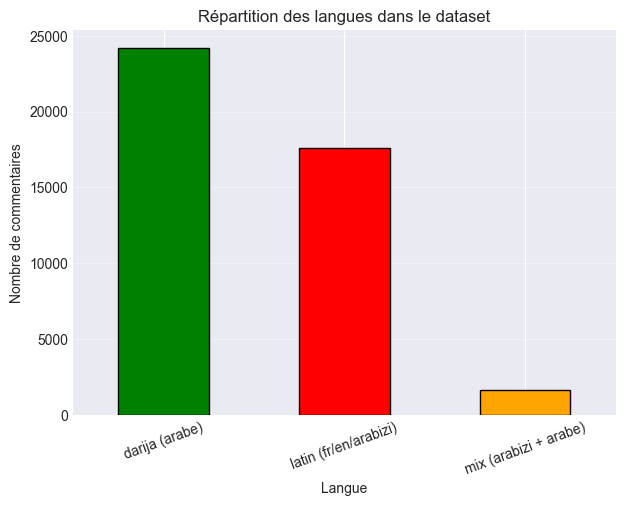


📌 Analyse qualitative des langues :

LANGUE : darija (arabe)
 Description : Texte écrit uniquement en arabe dialectal marocain.
Exemple 1 : فيناهو الفيديو نشوفوه شنو المشكل
Exemple 2 : بغينا بيمو و ناشيونال بداريجه


LANGUE : latin (fr/en/arabizi)
 Description : Texte écrit en alphabet latin .
Exemple 1 : lwalida haja a5ra
Exemple 2 : ahsan pisode saraha


LANGUE : mix (arabizi + arabe)
 Description : Mélange d'arabe et de latin dans le même commentaire.
Exemple 1 : 190 dh لغدس
Exemple 2 : no chill مروان خرج معاه all in




In [52]:
import matplotlib.pyplot as plt
import re

# 🔍 Détection de langue améliorée
def detect_language(text):
    text = str(text)

    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    has_latin = bool(re.search(r'[a-zA-Z]', text))

    if has_arabic and has_latin:
        return "mix (arabizi + arabe)"
    elif has_arabic:
        return "darija (arabe)"
    elif has_latin:
        return "latin (fr/en/arabizi)"
    else:
        return "autre"

# 📌 Application
df["language"] = df["text_clean"].apply(detect_language)

#  Comptage
lang_counts = df["language"].value_counts()

print("\n Répartition des langues :")
display(lang_counts)

# 📈 Graphe
plt.figure(figsize=(7,5))
colors = ["green", "red", "orange", "purple"]

lang_counts.plot(
    kind="bar",
    color=colors[:len(lang_counts)],
    edgecolor="black"
)
plt.title("Répartition des langues dans le dataset")
plt.xlabel("Langue")
plt.ylabel("Nombre de commentaires")
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.show()

# =========================================================
# 📌 EXPLICATION + EXEMPLES PAR LANGUE
# =========================================================

print("\n📌 Analyse qualitative des langues :\n")

language_description = {
    "darija (arabe)": "Texte écrit uniquement en arabe dialectal marocain.",
    "latin (fr/en/arabizi)": "Texte écrit en alphabet latin .",
    "mix (arabizi + arabe)": "Mélange d'arabe et de latin dans le même commentaire.",
    "autre": "Texte non standard ou vide."
}

for lang in df["language"].unique():

    print("=" * 70)
    print(f"LANGUE : {lang}")
    print(f" Description : {language_description.get(lang, 'Non défini')}")
    print("=" * 70)

    samples = df[df["language"] == lang]["text_clean"].dropna()

    if len(samples) > 0:
        samples = samples.sample(min(2, len(samples)), random_state=42)

        for i, ex in enumerate(samples, 1):
            print(f"Exemple {i} : {ex}")

    print("\n")